## Bank Marketing – Machine Learning Model Building

### Objective
The objective of this notebook is to train and evaluate five
classification algorithms using the cleaned Bank Marketing dataset.

### Machine Learning Algorithms
1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

### Evaluation Metrics
- Accuracy
- AUC
- Precision
- Recall
- F1-score
- Matthews Correlation Coefficient (MCC)

### 1. Import libraries and create output folders

In [1]:
import os
import sys
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
os.makedirs("../models", exist_ok=True)
os.makedirs("../results", exist_ok=True)

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("Libraries imported and output folders ready.")

Python: 3.9.19 (main, Sep 11 2024, 00:00:00) 
[GCC 11.5.0 20240719 (Red Hat 11.5.0-2)]
scikit-learn: 1.5.2
Libraries imported and output folders ready.


### 2. Load and inspect the cleaned dataset

The preprocessing notebook should already have:
- removed duplicate rows;
- excluded `duration` to avoid using a feature only known after the call;
- converted the target `y` to numeric values (`no = 0`, `yes = 1`);
- saved the resulting data as `dataset/cleaned_bank_marketing.csv`.

Encoding and scaling are deliberately performed inside the model pipelines below. This allows each transformation to be fitted on training folds only, avoiding data leakage during cross-validation.

In [2]:
DATA_PATH = "../data/cleaned_bank_marketing.csv"

df = pd.read_csv(DATA_PATH)

if "y" not in df.columns:
    raise ValueError("Target column 'y' was not found in the cleaned dataset.")

# Ensure target is numeric 0/1, accommodating either numeric or yes/no input.
if df["y"].dtype == "object":
    target_map = {"no": 0, "yes": 1}
    df["y"] = df["y"].str.strip().str.lower().map(target_map)

if df["y"].isna().any():
    raise ValueError("Target column contains missing or unrecognized values.")

df["y"] = df["y"].astype(int)

# The duration feature should have been removed in data_processing.ipynb.
if "duration" in df.columns:
    print("Warning: 'duration' is present and will be excluded from predictors.")
    df = df.drop(columns=["duration"])

print("Dataset shape:", df.shape)
display(df.head())
print("\nTarget distribution:")
display(df["y"].value_counts().rename(index={0: "no (0)", 1: "yes (1)"}))

Dataset shape: (45211, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown,0



Target distribution:


y
no (0)     39922
yes (1)     5289
Name: count, dtype: int64

### 3. Separate predictors and target

In [3]:
X = df.drop(columns=["y"]).copy()
y = df["y"].copy()

print("Number of predictor features:", X.shape[1])
print("Target values:", sorted(y.unique()))

if X.shape[1] < 12:
    raise ValueError(f"Only {X.shape[1]} predictor columns found; verify the dataset.")

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nNumeric feature count:", len(numeric_features))
print("Categorical feature count:", len(categorical_features))

Number of predictor features: 15
Target values: [0, 1]

Numeric features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Numeric feature count: 6
Categorical feature count: 9


### 4. Train-test split

An 80:20 stratified split is used. The test set is held out until final evaluation. Do not use it to select hyperparameters.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training predictors:", X_train.shape)
print("Test predictors:", X_test.shape)
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True))
print("\nTest target proportions:")
display(y_test.value_counts(normalize=True))

Training predictors: (36168, 15)
Test predictors: (9043, 15)

Training target proportions:


y
0    0.883018
1    0.116982
Name: proportion, dtype: float64


Test target proportions:


y
0    0.883003
1    0.116997
Name: proportion, dtype: float64

### 5. Build a fresh preprocessing pipeline for each model

Numerical columns are median-imputed and standardized. Categorical columns are imputed with the most frequent value and one-hot encoded. `handle_unknown='ignore'` allows the application to handle categories not seen during training.

The encoder compatibility helper supports both newer and older scikit-learn versions.

In [5]:
def make_one_hot_encoder():
    # scikit-learn >= 1.2 uses sparse_output; older versions use sparse.
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def create_preprocessor():
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", make_one_hot_encoder())
    ])

    return ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features)
        ],
        remainder="drop"
    )

print("Preprocessing pipeline function is ready.")

Preprocessing pipeline function is ready.


### 6. Define baseline models

These baseline models use reasonable initial settings. We evaluate them first, then compare them with their tuned counterparts.

In [6]:
baseline_estimators = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12, min_samples_split=10,
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights="distance"),
    "Gaussian Naive Bayes": GaussianNB(),
    "SVM": LinearSVC(
        C=1.0, class_weight="balanced",
        random_state=RANDOM_STATE, max_iter=5000
    )
}

baseline_models = {}
for name, estimator in baseline_estimators.items():
    baseline_models[name] = Pipeline(steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", estimator)
    ])

print("Five baseline pipelines created.")

Five baseline pipelines created.


### 7. Train and evaluate baseline models

ROC-AUC is calculated from predicted probabilities when available, otherwise from the decision scores. The positive class is `1` (subscription = yes).

In [7]:
def calculate_metrics(model, X_eval, y_true):
    y_pred = model.predict(X_eval)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_eval)[:, 1]
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_eval)
    else:
        y_score = y_pred

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, y_score),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred)
    }


baseline_results = []
for name, pipeline in baseline_models.items():
    print("Training baseline:", name)
    pipeline.fit(X_train, y_train)

    row = {"Model": name}
    row.update(calculate_metrics(pipeline, X_test, y_test))
    baseline_results.append(row)

baseline_metrics_df = pd.DataFrame(baseline_results)
display(baseline_metrics_df.sort_values("F1 Score", ascending=False))

baseline_metrics_df.to_csv("../results/baseline_model_metrics.csv", index=False)
print("Baseline metrics saved.")

Training baseline: Logistic Regression
Training baseline: Decision Tree
Training baseline: KNN
Training baseline: Gaussian Naive Bayes
Training baseline: SVM


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
1,Decision Tree,0.830477,0.722214,0.350347,0.525520,0.420416,0.334947
3,Gaussian Naive Bayes,0.845184,0.751425,0.370846,0.464083,0.412259,0.327093
4,SVM,0.757824,0.771755,0.268412,0.620038,0.374643,0.286692
0,Logistic Regression,0.754838,0.772238,0.266236,0.623819,0.373198,0.285345
2,KNN,0.889085,0.713810,0.575758,0.197543,0.294159,0.291885


Baseline metrics saved.


### 8. Define cross-validation and hyperparameter search spaces

`StratifiedKFold` preserves the class proportions in each fold. `GridSearchCV` selects hyperparameters using mean cross-validation F1-score. The preprocessing pipeline is part of the estimator, so it is refitted separately inside each training fold.

In [8]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.1, 1, 10],
        "classifier__solver": ["lbfgs", "liblinear"]
    },
    "Decision Tree": {
        "classifier__max_depth": [8, 12, 16],
        "classifier__min_samples_split": [10, 20],
        "classifier__min_samples_leaf": [5, 10],
        "classifier__criterion": ["gini", "entropy"]
    },
    "KNN": {
        "classifier__n_neighbors": [5, 7, 11],
        "classifier__weights": ["uniform", "distance"],
        "classifier__p": [1, 2]
    },
    "Gaussian Naive Bayes": {
        "classifier__var_smoothing": [1e-9, 1e-8, 1e-7]
    },
    "SVM": {
        "classifier__C": [0.01, 0.1, 1],
        "classifier__loss": ["hinge", "squared_hinge"]
    }
}

print("5-fold stratified cross-validation configured.")
for model_name, grid in param_grids.items():
    combinations = int(np.prod([len(v) for v in grid.values()]))
    print(f"{model_name}: {combinations} parameter combinations")

5-fold stratified cross-validation configured.
Logistic Regression: 6 parameter combinations
Decision Tree: 24 parameter combinations
KNN: 12 parameter combinations
Gaussian Naive Bayes: 3 parameter combinations
SVM: 6 parameter combinations


### 9. Tune all five models using GridSearchCV

This cell may take some time, especially KNN and the larger Decision Tree search. `n_jobs=-1` uses available CPU cores. If the lab runs out of memory or the cell is excessively slow, reduce the search grid or use fewer parallel jobs (for example, `n_jobs=1`).

In [9]:
best_models = {}
best_preprocessors = {}
tuning_results = []
grid_search_objects = {}

for model_name, estimator in baseline_estimators.items():
    print("\n" + "=" * 65)
    print("Hyperparameter tuning:", model_name)
    print("=" * 65)

    pipeline = Pipeline(steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", estimator)
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[model_name],
        scoring="f1",
        cv=cv_strategy,
        n_jobs=-1,
        verbose=1,
        refit=True,
        return_train_score=False
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    best_models[model_name] = best_model
    best_preprocessors[model_name] = best_model.named_steps["preprocessor"]
    grid_search_objects[model_name] = grid_search

    tuning_results.append({
        "Model": model_name,
        "Best CV F1 Score": grid_search.best_score_,
        "Best Parameters": json.dumps(grid_search.best_params_)
    })

    print("Best CV F1:", round(grid_search.best_score_, 4))
    print("Best parameters:", grid_search.best_params_)

tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df.to_csv("../results/hyperparameter_tuning_results.csv", index=False)

display(tuning_results_df.sort_values("Best CV F1 Score", ascending=False))
print("Hyperparameter tuning completed and results saved.")


Hyperparameter tuning: Logistic Regression
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best CV F1: 0.3728
Best parameters: {'classifier__C': 10, 'classifier__solver': 'liblinear'}

Hyperparameter tuning: Decision Tree
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best CV F1: 0.419
Best parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 20}

Hyperparameter tuning: KNN
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV F1: 0.3065
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 1, 'classifier__weights': 'distance'}

Hyperparameter tuning: Gaussian Naive Bayes
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best CV F1: 0.3925
Best parameters: {'classifier__var_smoothing': 1e-09}

Hyperparameter tuning: SVM
Fitting 5 folds for each of 6 candidates, totalling 30 fits


/home/s2026ak05548/.local/lib/python3.9/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/s2026ak05548/.local/lib/python3.9/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/s2026ak05548/.local/lib/python3.9/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/s2026ak05548/.local/lib/python3.9/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/s2026ak05548/.local/lib/python3.9/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/s2026ak05548/.local/lib/python3.9/site-packages/sklearn/svm/_base.py:1235: Conv

Best CV F1: 0.3841
Best parameters: {'classifier__C': 0.01, 'classifier__loss': 'hinge'}


,Model,Best CV F1 Score,Best Parameters
1,Decision Tree,0.418977,"{""classifier__criterion"": ""entropy"", ""classifi..."
3,Gaussian Naive Bayes,0.392484,"{""classifier__var_smoothing"": 1e-09}"
4,SVM,0.384058,"{""classifier__C"": 0.01, ""classifier__loss"": ""h..."
0,Logistic Regression,0.372787,"{""classifier__C"": 10, ""classifier__solver"": ""l..."
2,KNN,0.306500,"{""classifier__n_neighbors"": 5, ""classifier__p""..."


Hyperparameter tuning completed and results saved.


### 10. Save each fitted preprocessor and complete tuned pipeline

The complete pipeline is the preferred artifact for Streamlit: it automatically applies the exact fitted preprocessing steps and then predicts. The standalone preprocessor files are also saved separately for inspection or workflows where transformed features are needed independently.

In [10]:
for model_name, best_model in best_models.items():
    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    pipeline_path = f"../models/{safe_name}_tuned_pipeline.joblib"
    preprocessor_path = f"../models/{safe_name}_preprocessor.joblib"

    joblib.dump(best_model, pipeline_path)
    joblib.dump(best_model.named_steps["preprocessor"], preprocessor_path)

    print("Saved:", pipeline_path)
    print("Saved:", preprocessor_path)

Saved: ../models/logistic_regression_tuned_pipeline.joblib
Saved: ../models/logistic_regression_preprocessor.joblib
Saved: ../models/decision_tree_tuned_pipeline.joblib
Saved: ../models/decision_tree_preprocessor.joblib
Saved: ../models/knn_tuned_pipeline.joblib
Saved: ../models/knn_preprocessor.joblib
Saved: ../models/gaussian_naive_bayes_tuned_pipeline.joblib
Saved: ../models/gaussian_naive_bayes_preprocessor.joblib
Saved: ../models/svm_tuned_pipeline.joblib
Saved: ../models/svm_preprocessor.joblib


### 11. Evaluate tuned models on the independent test set

The test set is used only after hyperparameter selection is complete. These metrics are the final held-out results for the tuned models.

In [11]:
tuned_results = []
tuned_predictions = {}

for model_name, best_model in best_models.items():
    row = {"Model": model_name}
    row.update(calculate_metrics(best_model, X_test, y_test))
    tuned_results.append(row)

    tuned_predictions[model_name] = best_model.predict(X_test)

tuned_metrics_df = pd.DataFrame(tuned_results)
tuned_metrics_df.to_csv("../results/tuned_model_metrics.csv", index=False)

display(tuned_metrics_df.sort_values("F1 Score", ascending=False))
print("Tuned test metrics saved.")

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
1,Decision Tree,0.825169,0.766109,0.347699,0.564272,0.430270,0.347486
3,Gaussian Naive Bayes,0.845184,0.751425,0.370846,0.464083,0.412259,0.327093
4,SVM,0.791662,0.765039,0.295342,0.563327,0.387516,0.297393
0,Logistic Regression,0.755391,0.772202,0.266586,0.622873,0.373371,0.285457
2,KNN,0.887427,0.711919,0.544444,0.231569,0.324934,0.304333


Tuned test metrics saved.


### 12. Compare baseline and tuned performance

A positive difference indicates improvement in that metric; a negative difference indicates a decrease. Tuning does not guarantee improvement on every metric.

In [12]:
comparison_df = baseline_metrics_df.merge(
    tuned_metrics_df,
    on="Model",
    suffixes=("_Baseline", "_Tuned")
)

metrics_to_compare = [
    "Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC"
]

for metric in metrics_to_compare:
    comparison_df[metric + "_Change"] = (
        comparison_df[metric + "_Tuned"]
        - comparison_df[metric + "_Baseline"]
    )

comparison_df.to_csv("../results/baseline_vs_tuned_comparison.csv", index=False)
display(comparison_df)

,Model,Accuracy_Baseline,AUC_Baseline,Precision_Baseline,Recall_Baseline,F1 Score_Baseline,MCC_Baseline,Accuracy_Tuned,AUC_Tuned,Precision_Tuned,Recall_Tuned,F1 Score_Tuned,MCC_Tuned,Accuracy_Change,AUC_Change,Precision_Change,Recall_Change,F1 Score_Change,MCC_Change
0,Logistic Regression,0.754838,0.772238,0.266236,0.623819,0.373198,0.285345,0.755391,0.772202,0.266586,0.622873,0.373371,0.285457,0.000553,-0.000036,0.000349,-0.000945,0.000173,0.000112
1,Decision Tree,0.830477,0.722214,0.350347,0.525520,0.420416,0.334947,0.825169,0.766109,0.347699,0.564272,0.430270,0.347486,-0.005308,0.043895,-0.002647,0.038752,0.009854,0.012539
2,KNN,0.889085,0.713810,0.575758,0.197543,0.294159,0.291885,0.887427,0.711919,0.544444,0.231569,0.324934,0.304333,-0.001659,-0.001891,-0.031313,0.034026,0.030775,0.012448
3,Gaussian Naive Bayes,0.845184,0.751425,0.370846,0.464083,0.412259,0.327093,0.845184,0.751425,0.370846,0.464083,0.412259,0.327093,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,SVM,0.757824,0.771755,0.268412,0.620038,0.374643,0.286692,0.791662,0.765039,0.295342,0.563327,0.387516,0.297393,0.033838,-0.006716,0.026929,-0.056711,0.012873,0.010702


### 13. Visualize baseline versus tuned F1-score

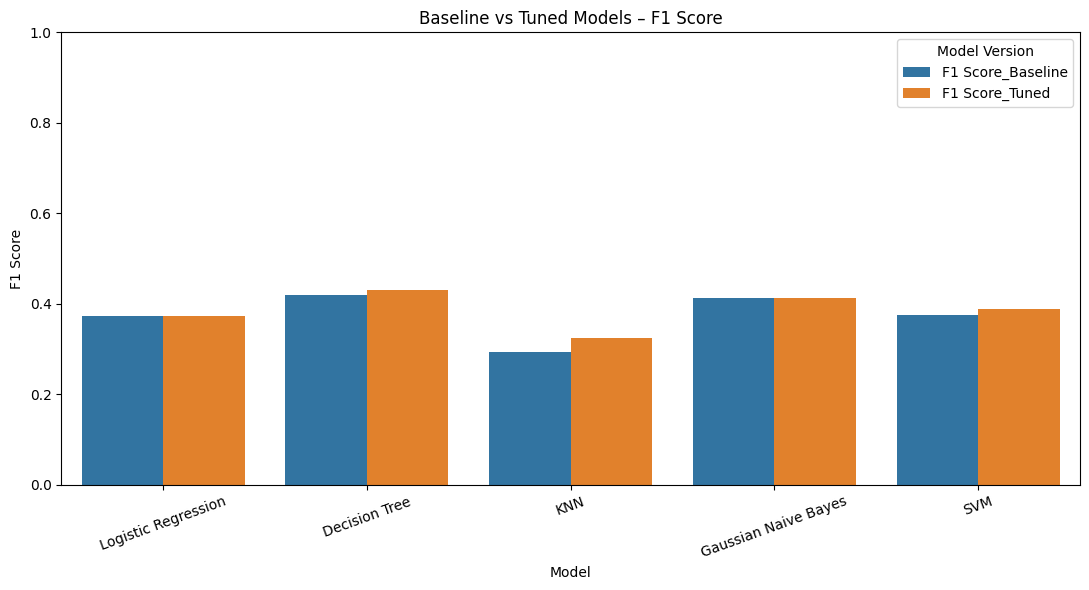

In [13]:
plot_df = comparison_df[["Model", "F1 Score_Baseline", "F1 Score_Tuned"]].melt(
    id_vars="Model",
    var_name="Model Version",
    value_name="F1 Score"
)

plt.figure(figsize=(11, 6))
sns.barplot(data=plot_df, x="Model", y="F1 Score", hue="Model Version")
plt.title("Baseline vs Tuned Models – F1 Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("../results/baseline_vs_tuned_f1.png", dpi=300)
plt.show()

### 14. Confusion matrices and classification reports for tuned models


Logistic Regression
              precision    recall  f1-score   support

          No       0.94      0.77      0.85      7985
         Yes       0.27      0.62      0.37      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.76      0.79      9043



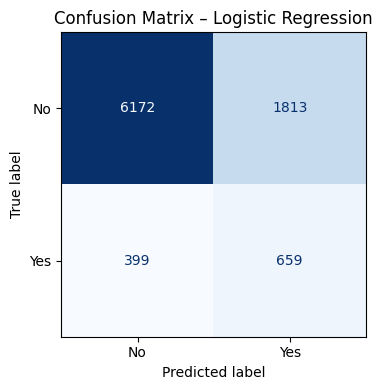


Decision Tree
              precision    recall  f1-score   support

          No       0.94      0.86      0.90      7985
         Yes       0.35      0.56      0.43      1058

    accuracy                           0.83      9043
   macro avg       0.64      0.71      0.66      9043
weighted avg       0.87      0.83      0.84      9043



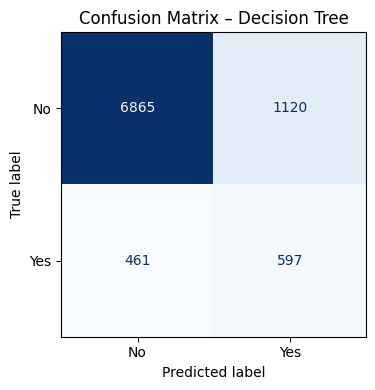


KNN
              precision    recall  f1-score   support

          No       0.91      0.97      0.94      7985
         Yes       0.54      0.23      0.32      1058

    accuracy                           0.89      9043
   macro avg       0.72      0.60      0.63      9043
weighted avg       0.86      0.89      0.87      9043



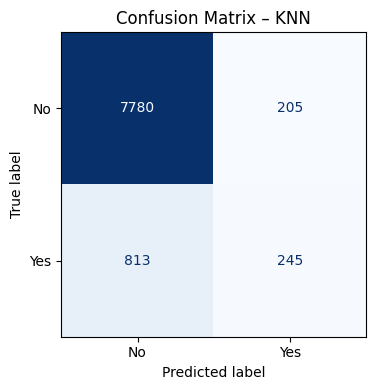


Gaussian Naive Bayes
              precision    recall  f1-score   support

          No       0.93      0.90      0.91      7985
         Yes       0.37      0.46      0.41      1058

    accuracy                           0.85      9043
   macro avg       0.65      0.68      0.66      9043
weighted avg       0.86      0.85      0.85      9043



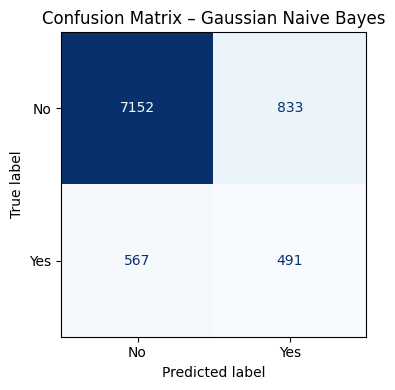


SVM
              precision    recall  f1-score   support

          No       0.93      0.82      0.87      7985
         Yes       0.30      0.56      0.39      1058

    accuracy                           0.79      9043
   macro avg       0.61      0.69      0.63      9043
weighted avg       0.86      0.79      0.82      9043



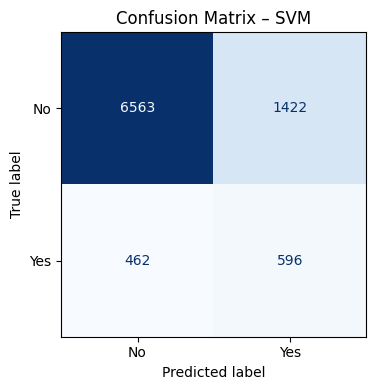

In [14]:
for model_name, y_pred in tuned_predictions.items():
    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)
    print(classification_report(
        y_test, y_pred,
        target_names=["No", "Yes"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred)
    display_labels = ["No", "Yes"]

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=display_labels
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(f"Confusion Matrix – {model_name}")
    plt.tight_layout()

    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
    plt.savefig(f"../results/{safe_name}_confusion_matrix.png", dpi=300)
    plt.show()

    with open(f"../results/{safe_name}_classification_report.txt", "w") as file:
        file.write(classification_report(
            y_test, y_pred,
            target_names=["No", "Yes"],
            zero_division=0
        ))

### 15. Select the best tuned model

For this project, the leading model is identified by held-out test F1-score. Review AUC, recall, precision, and MCC as well before making a final recommendation, because the most appropriate model depends on the cost of false positives and false negatives.

In [15]:
best_row = tuned_metrics_df.sort_values("F1 Score", ascending=False).iloc[0]
best_model_name = best_row["Model"]
best_model = best_models[best_model_name]

print("Best model by test F1-score:", best_model_name)
print("\nTest metrics:")
display(best_row.to_frame(name="Value"))

print("\nSelected model's best hyperparameters:")
print(grid_search_objects[best_model_name].best_params_)

Best model by test F1-score: Decision Tree

Test metrics:


,Value
Model,Decision Tree
Accuracy,0.825169
AUC,0.766109
Precision,0.347699
Recall,0.564272
F1 Score,0.43027
MCC,0.347486



Selected model's best hyperparameters:
{'classifier__criterion': 'entropy', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 20}


### 16. Save the held-out test dataset for Streamlit evaluation

This file contains the original predictor columns and the true target `y`. Upload it to the Streamlit app to evaluate models. It is a test dataset, not training data.

In [16]:
test_data = X_test.copy()
test_data["y"] = y_test.values

test_data.to_csv("../data/test_data.csv", index=False)

print("Test data saved to test_data.csv")
print("Test data shape:", test_data.shape)
display(test_data.head())

Test data saved to test_data.csv
Test data shape: (9043, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
1392,40,blue-collar,married,primary,no,640,yes,yes,unknown,8,may,2,-1,0,unknown,0
7518,44,technician,married,secondary,no,378,yes,no,unknown,30,may,2,-1,0,unknown,0
12007,31,services,married,secondary,no,356,yes,no,unknown,20,jun,5,-1,0,unknown,0
5536,36,blue-collar,married,primary,no,655,yes,no,unknown,23,may,4,-1,0,unknown,0
29816,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,1,-1,0,unknown,0


### 17. Final artifact and results inventory

In [17]:
print("MODEL FILES")
for filename in sorted(os.listdir("models")):
    print(" -", filename)

print("\nRESULT FILES")
for filename in sorted(os.listdir("results")):
    print(" -", filename)

print("\nMain outputs:")
print(" - results/baseline_model_metrics.csv")
print(" - results/hyperparameter_tuning_results.csv")
print(" - results/tuned_model_metrics.csv")
print(" - results/baseline_vs_tuned_comparison.csv")
print(" - test_data.csv")
print(" - models/*_tuned_pipeline.joblib")
print(" - models/*_preprocessor.joblib")

MODEL FILES


FileNotFoundError: [Errno 2] No such file or directory: 'models'